# Project II: Economic Growth 

This notebook will help you getting started with analyzing the growth dataset, `growth.csv`.

In [520]:
from sklearn.linear_model import Lasso
from scipy.stats import norm
import numpy.linalg as la
from sklearn.preprocessing import PolynomialFeatures
import pandas as pd 
import numpy as np 
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import seaborn as sns 

## Read data 

In [521]:
dat = pd.read_csv('growth.csv')
lbldf = pd.read_csv('labels.csv', index_col='variable')
lbl_all = lbldf.label.to_dict() # as a dictionary
print(f'The data contains {dat.shape[0]} rows (countries) and {dat.shape[1]} columns (variables).')

The data contains 214 rows (countries) and 85 columns (variables).


# Descriptive plots

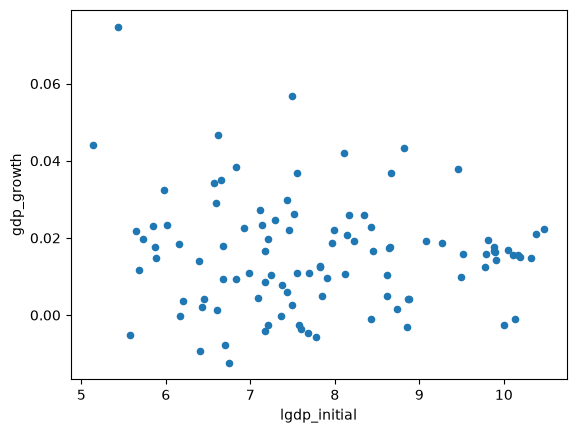

In [522]:
dat.plot.scatter(x='lgdp_initial', y='gdp_growth');

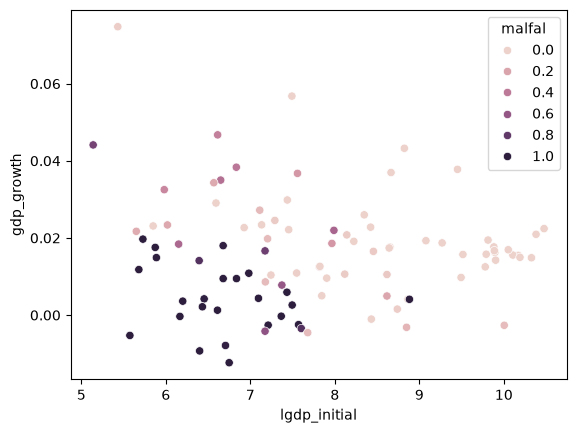

In [523]:

sns.scatterplot(x='lgdp_initial', y='gdp_growth', data=dat, hue='malfal');

# Collections of variables

In order to make the analysis simpler, it may be convenient to collect variables in sets that belong together naturally. 

In [524]:
# all available variables
vv_institutions = ['marketref', 'dem', 'demCGV', 'demBMR', 'demreg'] 
vv_geography = [
        'tropicar','distr', 'distcr', 'distc','suitavg','temp', 'suitgini', 'elevavg', 'elevstd',
        'kgatr', 'precip', 'area', 'abslat', 'cenlong', 'area_ar', 'rough','landlock', 
        'africa',  'asia', 'oceania', 'americas' # 'europe' is the reference
]
vv_geneticdiversity = ['pdiv', 'pdiv_aa', 'pdivhmi', 'pdivhmi_aa']
vv_historical = ['pd1000', 'pd1500', 'pop1000', 'pop1500', 'ln_yst'] # these are often missing: ['pd1', 'pop1']
vv_religion = ['pprotest', 'pcatholic', 'pmuslim']
vv_danger = ['yellow', 'malfal',  'uvdamage']
vv_resources = ['oilres', 'goldm', 'iron', 'silv', 'zinc']
vv_educ = ['ls_bl', 'lh_bl'] # secondary, tertiary: we exclude 'lp_bl' (primary) to avoid rank failure 

vv_all = {'institutions': vv_institutions, 
          'geography': vv_geography, 
          'geneticdiversity': vv_geneticdiversity,
          'historical': vv_historical,
          'religion': vv_religion,
          'danger':vv_danger, 
          'resources':vv_resources,
          'education':vv_educ
         }
list_of_lists = vv_all.values()
vv_all['all'] = [v for sublist in list_of_lists for v in sublist]


In [525]:
# Check sample size as control groups are added

groups = {
    'Investment and population': ['investment_rate', 'pop_growth'],
    'Geography': vv_geography,
    'Institutions': vv_institutions,
    'Genetic diversity': vv_geneticdiversity,
    'Historical': vv_historical,
    'Religion': vv_religion,
    'Disease environment': vv_danger,
    'Natural resources': vv_resources,
    'education': vv_educ,
}

current_controls = []

print("Baseline:",
      dat[['gdp_growth', 'lgdp_initial']].dropna().shape[0])

for group, variables in groups.items():

    current_controls += variables
    current_controls = list(dict.fromkeys(current_controls))

    required = ['gdp_growth', 'lgdp_initial'] + current_controls

    n = dat[required].dropna().shape[0]

    print(f"{group}: {n} observations")

Baseline: 102
Investment and population: 99 observations
Geography: 89 observations
Institutions: 76 observations
Genetic diversity: 65 observations
Historical: 62 observations
Religion: 62 observations
Disease environment: 62 observations
Natural resources: 62 observations
education: 58 observations


In [526]:
# convenient to keep a column of ones in the dataset
dat['constant'] = np.ones((dat.shape[0],))

# Simple OLS

In [527]:
# 1. avoiding missings 
I = dat[['gdp_growth', 'lgdp_initial']].notnull().all(axis=1)

# 2. extract dataset 
y = dat.loc[I, 'gdp_growth'].values.reshape((-1,1)) * 100.0
X = dat.loc[I, ['constant','lgdp_initial']].values

# 3. run OLS
betahat = np.linalg.inv(X.T @ X) @ X.T @ y
print(betahat)

[[ 2.24792211]
 [-0.08713416]]


# Adding more controls

In [528]:
vs = vv_all['geography'] + vv_all['religion']
xs = ['lgdp_initial', 'pop_growth', 'investment_rate'] + vs

# avoiding missings
all_vars = ['gdp_growth'] + xs
I = dat[all_vars].notnull().all(1)

# extract data
X = dat.loc[I, xs].values
y = dat.loc[I,'gdp_growth'].values.reshape((-1,1)) * 100. #easier to read output when growth is in 100%

# add const. (unless this breaks the rank condition)
oo = np.ones((I.sum(),1))
X = np.hstack([X, oo])
xs.append('constant') # we put it in as the last element

# check the rank condition
K = X.shape[1]
assert np.linalg.matrix_rank(X) == X.shape[1], f'X does not have full rank'

# compute the OLS estimator
betas = np.linalg.inv(X.T @ X) @ X.T @ y

/var/folders/xw/j6c1c3514_l7lyj6wyc6l1rc0000gn/T/ipykernel_20053/2288867945.py:6: Pandas4Warning: Starting with pandas version 4.0 all arguments of all will be keyword-only.
  I = dat[all_vars].notnull().all(1)


In [529]:
# format nicely
print(f'Mean y = {y.mean(): 5.2f}% growth per year')
pd.DataFrame({'β': betas[:,0]}, index=xs).round(3)

Mean y =  1.52% growth per year


,β
lgdp_initial,-1.118
pop_growth,6.830
investment_rate,0.068
tropicar,-0.411
distr,-0.000
distcr,0.001
distc,-0.003
suitavg,-1.063
temp,-0.204
suitgini,-0.771


In [530]:
# Define variables
y_var = 'gdp_growth'
d_var = 'lgdp_initial'

# Define candidate controls
control_vars = (
    ['investment_rate', 'pop_growth']
    + vv_all['all']
)


control_vars = list(dict.fromkeys(control_vars))

base_mask = dat[['gdp_growth', 'lgdp_initial']].notna().all(axis=1)

missing_report = pd.DataFrame({
    'Missing observations': dat.loc[base_mask, control_vars].isna().sum(),
    'Missing percentage': (
        dat.loc[base_mask, control_vars].isna().mean() * 100
    )
})

missing_report = missing_report.sort_values('Missing percentage')


max_missing = 0.10

missing_share = dat.loc[base_mask, control_vars].isna().mean()

keep_controls = missing_share[
    missing_share <= max_missing
].index.tolist()

dropped_controls = missing_share[
    missing_share > max_missing
].index.tolist()


model_data = dat.loc[
    base_mask,
    ['gdp_growth', 'lgdp_initial'] + keep_controls
].copy()


imputed_vars = []

for var in keep_controls:
    if model_data[var].isna().any():

        observed = model_data[var].dropna()

        if set(observed.unique()).issubset({0, 1}):
            fill_value = observed.mode().iloc[0]
        else:
            fill_value = observed.median()

        model_data[var] = model_data[var].fillna(fill_value)

        imputed_vars.append(var)

print("Variables imputed:", imputed_vars)

Variables imputed: ['investment_rate', 'demreg', 'tropicar', 'distr', 'distcr', 'distc', 'suitavg', 'temp', 'elevavg', 'elevstd', 'kgatr', 'precip', 'abslat', 'area_ar', 'rough', 'landlock', 'pdiv_aa', 'pd1000', 'pd1500', 'pop1000', 'pop1500', 'ln_yst', 'yellow', 'malfal', 'oilres', 'goldm', 'iron', 'silv', 'zinc']


In [531]:
poly_vars = keep_controls.copy()

poly = PolynomialFeatures(degree=1, include_bias=False)

poly_input = (
    model_data[poly_vars] - model_data[poly_vars].mean()
)

poly_array = poly.fit_transform(poly_input)

poly_names = poly.get_feature_names_out(poly_vars)

poly_df = pd.DataFrame(
    poly_array,
    columns=poly_names,
    index=model_data.index
)

new_features = poly_df.drop(columns=poly_vars)

model_data = pd.concat([model_data, new_features], axis=1)

keep_controls = keep_controls + new_features.columns.tolist()


print(new_features.columns.tolist())

sample = model_data

[]


In [532]:
y = sample['gdp_growth'].values * 100
d = sample['lgdp_initial'].values
Z = sample[keep_controls].values

control_vars = keep_controls

N = len(y)
p = Z.shape[1]


In [533]:
# Construct X 
X = np.column_stack((d,Z))

# Find N
N = X.shape[0]

### OLS

In [534]:
# Create a function for standardizing
def standardize(X):

    X_stan = (X - np.mean(X, axis=0))/np.std(X, axis=0, ddof=1)
    return X_stan

# Identify controls with positive, finite standard deviations
std_values = np.std(Z, axis=0, ddof=1)

keep = np.isfinite(std_values) & (std_values > 0)

# Update control variables
control_vars = [
    name for name, selected in zip(control_vars, keep)
    if selected
]

# Update Z
Z = Z[:, keep]

# Reconstruct X
X = np.column_stack((d, Z))

# Standardize again
Z_stan = standardize(Z)
X_stan = standardize(X)
d_stan = standardize(d)

# Check
print("NaNs in Z_stan:", np.isnan(Z_stan).sum())
print("Remaining controls:", len(control_vars))

NaNs in Z_stan: 0
Remaining controls: 41


### Post Single Lasso

In [535]:
# Combine treatment and controls
X = np.column_stack((d, Z))

# Calculate standard deviations
X_std = np.std(X, axis=0, ddof=1)

# Identify variables with zero or invalid standard deviations
keep = np.isfinite(X_std) & (X_std > 0)

# Keep track of which controls remain
keep_controls = keep[1:]

Z = Z[:, keep_controls]
control_vars = [
    name for name, selected in zip(control_vars, keep_controls)
    if selected
]

# Reconstruct X
X = np.column_stack((d, Z))

# Standardize
X_stan = (X - X.mean(axis=0)) / X.std(axis=0, ddof=1)

print("Remaining controls:", Z.shape[1])
print("NaNs in X_stan:", np.isnan(X_stan).sum())

Remaining controls: 41
NaNs in X_stan: 0


In [536]:
# Make a function that calculates BRT. Hint: You implemented a version of this last week
def BRT(X_tilde,y):
    (N,p) = X_tilde.shape
    sigma = np.std(y, ddof=1)
    c=1.1
    alpha=0.05

    penalty_BRT= (sigma*c)/np.sqrt(N)*norm.ppf(1-alpha/(2*p))

    return penalty_BRT

In [537]:
# Calculate BRT
penalty_BRTyx = BRT(X_stan, y)
print("lambda_BRT =",penalty_BRTyx.round(2))

lambda_BRT = 0.52


In [538]:
# Check for NaN values in X_stan
print("Total NaNs:", np.isnan(X_stan).sum())

# Identify columns containing NaNs
bad_cols = np.where(np.isnan(X_stan).any(axis=0))[0]

print("Columns containing NaNs:", bad_cols)

Total NaNs: 0
Columns containing NaNs: []


In [539]:
# Run Lasso 
fit_BRTyx = Lasso(penalty_BRTyx, max_iter=10000).fit(X_stan,y)
coefs=fit_BRTyx.coef_

# Save variables where coefficients are not zero
Z_J = Z[:,coefs[1:]!=0] # Note: We use Z and not Z_stan

# Display number of variables in Z_J
print("The number of variables in Z_J is {}".format(Z_J.shape[1]))

# Identify selected control variables
selected_mask = coefs[1:] != 0

selected_controls = np.array(control_vars)[selected_mask]


for variable in selected_controls:
    print(variable)

The number of variables in Z_J is 3
asia
pop1500
malfal


In [540]:
# Add a constant to X
xx = np.column_stack((np.ones(N),d,Z_J))
yy = np.array(y).reshape(-1,1)

# Calculate OLS estimate
coefs_PSL = la.inv(xx.T@xx)@xx.T@yy
alpha_PSL = coefs_PSL[1][0]

# Calculate residuals
res_PSL = yy - xx@coefs_PSL

# Display alpha
print("alpha_PSL = ",alpha_PSL.round(2))

alpha_PSL =  -0.3


In [541]:
# Estimate variance
SSR = res_PSL.T@res_PSL
sigma2_PSL = SSR/(N-xx.shape[1])
var = sigma2_PSL*la.inv(xx.T@xx)

# Calculate standard errors
se = np.sqrt(np.diagonal(var)).reshape(-1, 1)
se_PSL=se[1][0]

# Display standard error
print("se_PSL = ",se_PSL.round(2))


se_PSL =  0.11


In [542]:
# Calculate the z statistic that corresponds to the 95% confidence interval of a two-sided test
q = norm.ppf(1-0.025)

# Calculate confidence interval
CI_low_PSL  = alpha_PSL-q*se_PSL
CI_high_PSL = alpha_PSL+q*se_PSL

# Display confidence interval
CI_PSL =  (((alpha_PSL-q*se_PSL).round(2),(alpha_PSL+q*se_PSL).round(2)))
print("CI_PSL = ",(CI_low_PSL.round(2),CI_high_PSL.round(2)))

CI_PSL =  (np.float64(-0.51), np.float64(-0.08))


### Post Double Lasso

In [543]:
# Calculate BRT
penalty_BRTyx = BRT(X_stan,y)
print("lambda_BRT =",penalty_BRTyx.round(2))

lambda_BRT = 0.52


In [544]:
# Run Lasso 
fit_BRTyx = Lasso(penalty_BRTyx, max_iter=10000).fit(X_stan, y)
coefs=fit_BRTyx.coef_


# Calculate residuals
resyx = y-fit_BRTyx.predict(X_stan)

# Calculate Y - Z@gamma (epsilon + alpha*d)
# Hint: You only need the variables given to you in this cell, in addition
# to a standardized data set you made previoously.
resyxz = resyx + d_stan*coefs[0]

# Display first coefficient
print("First coefficient =",coefs[0].round(2))

First coefficient = 0.0


In [545]:
# Calculate BRT
penalty_BRTdz = BRT(Z_stan, d)

In [546]:
# Run Lasso
fit_BRTdz = Lasso(penalty_BRTdz, max_iter=10000).fit(Z_stan, d)
coefs=fit_BRTdz.coef_

# Calculate residuals
resdz=d-fit_BRTdz.predict(Z_stan)

# Display first coefficient
print("First coefficient =",coefs[0].round(2))

First coefficient = 0.0


In [547]:
# Calculate alpha
num = resdz@resyxz
denom = resdz@d
alpha_PDL = num/denom

# Display alpha
print("alpha_PDL = ",alpha_PDL.round(2))

alpha_PDL =  -0.23


In [548]:
# Calculate variance    
num = resdz**2@resyx**2/N
denom = (resdz.T@resdz/N)**2
sigma2_PDL = num/denom

# Display variance
print("sigma2_PDL = ",sigma2_PDL.round(2))

sigma2_PDL =  2.7


In [549]:
se_PDL = np.sqrt(sigma2_PDL/N)

print("se_PDL = ",se_PDL.round(2))

se_PDL =  0.16


In [550]:
q = norm.ppf(1-0.025)

CI_low_PDL  = alpha_PDL - q * se_PDL
CI_high_PDL = alpha_PDL + q * se_PDL

print("CI_PDL = ",(CI_low_PDL.round(2),CI_high_PDL.round(2)))

CI_PDL =  (np.float64(-0.55), np.float64(0.09))


In [551]:
results = {
           'PSL': [alpha_PSL, se_PSL, CI_low_PSL, CI_high_PSL],
           'PDL': [alpha_PDL, se_PDL, CI_low_PDL, CI_high_PDL]
            }


df_results = pd.DataFrame.from_dict(results, orient='index', columns=['Estimate of alpha', 'Standard error', 'Low bound of CI', 'High bound of CI'])


df_results = df_results.round(2)


df_results


,Estimate of alpha,Standard error,Low bound of CI,High bound of CI
PSL,-0.30,0.11,-0.51,-0.08
PDL,-0.23,0.16,-0.55,0.09


### PPOL


In [552]:
penalty_BRTyz = BRT(Z_stan, y)
print("lambda_BRT =",penalty_BRTyz.round(2))

lambda_BRT = 0.51


In [553]:

fit_BRTyz = Lasso(penalty_BRTyz, max_iter=10000).fit(Z_stan,y)
coefs=fit_BRTyz.coef_


resyz = y-fit_BRTyz.predict(Z_stan)

resyz

array([-1.11173484,  0.02637637,  0.24312285, -1.94769693,  0.10257661,
       -0.47336477,  0.54852224,  0.42630445, -1.61114361,  0.46738313,
       -0.4835691 ,  0.13224239,  3.18783413, -2.34923435,  0.75729052,
        5.37620653, -1.66849903, -0.47410202, -1.15898449,  0.36171567,
        0.39026437,  0.1347608 , -0.03557019,  1.46224037, -0.56578871,
       -0.25290162,  1.37756314,  0.03991377,  0.42363324, -0.41495252,
       -0.12189427, -1.01015005,  0.04969136, -0.6610963 , -0.33495908,
       -1.29203387, -1.05772159, -0.54738482, -0.42931173,  0.72760989,
        1.77149216, -0.6506722 , -1.67990481,  1.6100361 ,  1.23774225,
        2.25519034, -2.23413287,  0.53168086, -0.28661132, -1.62509991,
       -0.02571788, -2.07320678,  3.75048892,  1.52392512,  0.7894021 ,
        0.72080985,  0.74352315, -2.65423698, -0.47337424,  0.06888158,
        2.68883055,  2.55477403, -1.78318229, -0.23955712,  1.77569262,
       -2.20955238, -0.83239378, -1.96639349,  0.0338814 ,  0.57

In [554]:
penalty_BRTdz = BRT(Z_stan, d)
print("lambda_BRT =",penalty_BRTdz.round(2))

lambda_BRT = 0.48


In [555]:
fit_BRTdz = Lasso(penalty_BRTdz, max_iter=10000).fit(Z_stan,d)
coefs=fit_BRTdz.coef_


resdz = d-fit_BRTdz.predict(Z_stan)


resdz

array([ 8.12818968e-01,  2.19208883e+00,  1.29823852e+00, -1.70388468e+00,
        1.23222291e+00, -6.55068041e-01, -1.56342270e+00, -1.80603535e+00,
        2.19732723e+00, -6.64270868e-01, -3.51742450e-01,  7.49691658e-01,
       -1.01437965e+00, -8.52555200e-01,  1.88333212e-01, -2.62981875e+00,
        1.98852706e-01, -4.78270380e-01,  8.86587784e-02,  2.18554406e-01,
        3.73598814e-01,  1.22365482e+00,  1.59494986e+00, -2.50574956e-01,
        3.71397476e-02,  2.87642325e-01, -1.20686233e+00,  1.31616051e+00,
        1.03030976e+00, -4.53521392e-02,  1.33481017e+00,  1.44885687e+00,
        1.06498953e+00, -4.44045377e-01, -3.68065913e-01, -7.76571738e-01,
       -1.14754675e+00,  1.14168209e+00, -1.14837315e-01,  4.71129638e-01,
        7.96482067e-01, -4.91354570e-01, -1.60532200e-01, -7.87311625e-01,
       -1.85734440e+00,  7.45052718e-01,  9.75678587e-01, -6.84844125e-01,
        1.33277543e+00,  6.18887424e-01, -8.45473648e-01,  2.16422337e-01,
       -7.48604289e-01, -

In [556]:
num = resdz.T@resyz
denom = resdz.T@resdz
alpha_PPOL = num/denom


print("alpha_PPOL = ",alpha_PPOL.round(2))

alpha_PPOL =  -0.28


In [557]:

num = resyz**2 @ resdz**2 / N
denom = (resdz.T@resdz / N)**2
sigma2_PPOL = num/denom


print("sigma2_PDL = ",sigma2_PPOL.round(2))

sigma2_PDL =  2.69


In [558]:

se_PPOL = np.sqrt(sigma2_PPOL/N)


print("se_PDL = ",se_PPOL.round(2))

se_PDL =  0.16


In [559]:
q = norm.ppf(1-0.025)


CI_low_PPOL  = alpha_PPOL - q * se_PPOL
CI_high_PPOL = alpha_PPOL + q * se_PPOL


print("CI_PDL = ",(CI_low_PPOL.round(2),CI_high_PPOL.round(2)))

CI_PDL =  (np.float64(-0.6), np.float64(0.04))


In [560]:
results = {
           'PSL'   : [alpha_PSL,    se_PSL,    CI_low_PSL,    CI_high_PSL],
           'PDL'   : [alpha_PDL,    se_PDL,    CI_low_PDL,    CI_high_PDL],
           'PPOL'  : [alpha_PPOL,   se_PPOL,   CI_low_PPOL,   CI_high_PPOL]}


df_results = pd.DataFrame.from_dict(results, orient='index', columns=['Estimate of alpha', 'Standard error', 'Low bound of CI', 'High bound of CI'])

df_results = df_results.round(2)


df_results


,Estimate of alpha,Standard error,Low bound of CI,High bound of CI
PSL,-0.30,0.11,-0.51,-0.08
PDL,-0.23,0.16,-0.55,0.09
PPOL,-0.28,0.16,-0.60,0.04


In [561]:

selected_y_PDL = np.array(control_vars)[
    fit_BRTyx.coef_[1:] != 0
]

selected_d_PDL = np.array(control_vars)[
    fit_BRTdz.coef_ != 0
]

print("PDL controls selected for Y:", selected_y_PDL)
print("PDL controls selected for D:", selected_d_PDL)

PDL controls selected for Y: ['asia' 'pop1500' 'malfal']
PDL controls selected for D: ['demreg' 'malfal' 'uvdamage']


In [562]:
selected_y_PPOL = np.array(control_vars)[
    fit_BRTyz.coef_ != 0
]

selected_d_PPOL = np.array(control_vars)[
    fit_BRTdz.coef_ != 0
]
print(selected_y_PPOL)
print(selected_d_PPOL)

['asia' 'pop1500' 'malfal']
['demreg' 'malfal' 'uvdamage']


In [563]:

X = np.column_stack((d, Z))

X_stan = standardize(X)
Z_stan = standardize(Z)

d_stan = X_stan[:, 0]

N = len(y)
p = Z.shape[1]


In [564]:
def BCCH(Xtechn, y):
    n, pnew = Xtechn.shape
    c = 1.1
    alpha = 0.05

    # Pilot penalty
    yXtechscale = (np.max(
        (Xtechn.T ** 2) @ ((y - np.mean(y)) ** 2) / n
    )) ** 0.5

    lambda_pilot_tech = c*norm.ppf(1-alpha/(2*pnew))*yXtechscale/np.sqrt(n)

    # Pilot estimates
    coef_pilot_tech = Lasso(
        alpha=lambda_pilot_tech, max_iter=1000000
    ).fit(Xtechn, y).coef_

    intercept_pilot_tech = Lasso(
        alpha=lambda_pilot_tech, max_iter=1000000
    ).fit(Xtechn, y).intercept_

    # Updated penalty
    res_tech = y - (intercept_pilot_tech + Xtechn @ coef_pilot_tech)

    resXtechscale = (
        np.max((Xtechn.T ** 2) @ (res_tech ** 2) / n)
    ) ** 0.5

    lambda_bcch_tech = c*norm.ppf(1-alpha/(2*pnew))*resXtechscale/np.sqrt(n)

    # Updated estimates
    fit_bcch_tech = Lasso(
        alpha=lambda_bcch_tech,
        max_iter=1000000
    ).fit(Xtechn, y)

    coef_bcch_tech = fit_bcch_tech.coef_
    sel_bcch_tech = (coef_bcch_tech != 0)

    return fit_bcch_tech, lambda_bcch_tech

In [565]:
def fit_lasso(X, y, method):

    if method == 'BRT':

        penalty = BRT(X, y)

        fit = Lasso(
            alpha=penalty,
            max_iter=1000000
        ).fit(X, y)

    elif method == 'BCCH':

        fit, penalty = BCCH(X, y)

    return fit, penalty

In [566]:
def run_estimators(method):
    
    fit_yx, penalty_yx = fit_lasso(X_stan, y, method)

    fit_dz, penalty_dz = fit_lasso(Z_stan, d, method)

    fit_yz, penalty_yz = fit_lasso(Z_stan, y, method)

    selected_mask = fit_yx.coef_[1:] != 0

    Z_J = Z[:, selected_mask]

    xx = np.column_stack((np.ones(N), d, Z_J))
    yy = np.asarray(y).reshape(-1, 1)

    # OLS estimate
    coefs_PSL = la.lstsq(xx, yy, rcond=None)[0]

    beta_PSL = coefs_PSL[1, 0]

    # Calculate residuals
    res_PSL = yy - xx @ coefs_PSL


    SSR = np.sum(res_PSL**2)

    sigma2_PSL = SSR / (N - xx.shape[1])

    var_PSL = sigma2_PSL * la.inv(xx.T @ xx)

    # Standard error of beta
    se_PSL = np.sqrt(var_PSL[1, 1])

    # Calculate residuals from Y on D and Z
    resyx = y - fit_yx.predict(X_stan)

    # Calculate Y - Z@gamma (excluding D)
    resyxz = resyx + fit_yx.coef_[0] * d_stan

    # Calculate residuals from D on Z
    resdz = d - fit_dz.predict(Z_stan)

    # Calculate PDL estimate
    # Following Exercise Set 5, equation (2)
    num_PDL = resdz @ resyxz
    denom_PDL = resdz @ resdz

    beta_PDL = num_PDL / denom_PDL

    # Calculate PDL variance
    # Use resyx (full outcome residual), NOT resyxz
    num_PDL = np.mean(resdz**2 * resyx**2)
    denom_PDL = np.mean(resdz**2)**2

    sigma2_PDL = num_PDL / denom_PDL

    # Standard error
    se_PDL = np.sqrt(sigma2_PDL / N)

    # Residuals from Y on Z
    resyz = y - fit_yz.predict(Z_stan)

    # Treatment residuals are the same as in PDL
    resdz = d - fit_dz.predict(Z_stan)

    # Calculate PPOL estimate
    num_PPOL = resdz @ resyz
    denom_PPOL = resdz @ resdz

    beta_PPOL = num_PPOL / denom_PPOL

    # Calculate PPOL variance
    num_PPOL = np.mean(resyz**2 * resdz**2)
    denom_PPOL = np.mean(resdz**2)**2

    sigma2_PPOL = num_PPOL / denom_PPOL

    # Standard error
    se_PPOL = np.sqrt(sigma2_PPOL / N)

    q = norm.ppf(0.975)

    # PSL
    CI_low_PSL = beta_PSL - q * se_PSL
    CI_high_PSL = beta_PSL + q * se_PSL

    # PDL
    CI_low_PDL = beta_PDL - q * se_PDL
    CI_high_PDL = beta_PDL + q * se_PDL

    # PPOL
    CI_low_PPOL = beta_PPOL - q * se_PPOL
    CI_high_PPOL = beta_PPOL + q * se_PPOL

    results = {
        'PSL': [
            beta_PSL, se_PSL, CI_low_PSL, CI_high_PSL
        ],
        'PDL': [
            beta_PDL, se_PDL, CI_low_PDL, CI_high_PDL
        ],
        'PPOL': [
            beta_PPOL, se_PPOL, CI_low_PPOL, CI_high_PPOL
        ]
    }

    # Save selected variables
    selected_variables = {
        'Y on D,Z': np.array(control_vars)[fit_yx.coef_[1:] != 0],
        'D on Z': np.array(control_vars)[fit_dz.coef_ != 0],
        'Y on Z': np.array(control_vars)[fit_yz.coef_ != 0]
    }


    # Save penalty values
    penalties = {
        'Y on D,Z': penalty_yx,
        'D on Z': penalty_dz,
        'Y on Z': penalty_yz
    }


    return results, selected_variables, penalties

In [567]:
# Store all results
all_results = {}

# Store selected variables
all_selected = {}

# Store penalty values
all_penalties = {}

# Run BRT
results_BRT, selected_BRT, penalties_BRT = run_estimators('BRT')

# Run BCCH
results_BCCH, selected_BCCH, penalties_BCCH = run_estimators('BCCH')

# Combine results
for method, results in [
    ('BRT', results_BRT),
    ('BCCH', results_BCCH),

]:
    for estimator, values in results.items():

        all_results[f'{estimator} - {method}'] = values


# Save selected variables
all_selected = {
    'BRT': selected_BRT,
    'BCCH': selected_BCCH,
}

# Save penalties
all_penalties = {
    'BRT': penalties_BRT,
    'BCCH': penalties_BCCH,

}

In [568]:
# Create a dictionary with all results
results = all_results

# Create dataframe
df_results = pd.DataFrame.from_dict(
    results,
    orient='index',
    columns=[
        'Estimate of beta',
        'Standard error',
        'Low bound of CI',
        'High bound of CI'
    ]
)

# Round to two decimals
df_results = df_results.round(2)

# Display results
df_results

,Estimate of beta,Standard error,Low bound of CI,High bound of CI
PSL - BRT,-0.30,0.11,-0.51,-0.08
PDL - BRT,-0.28,0.16,-0.60,0.04
PPOL - BRT,-0.28,0.16,-0.60,0.04
PSL - BCCH,-0.09,0.11,-0.30,0.12
PDL - BCCH,-0.12,0.12,-0.36,0.12
PPOL - BCCH,-0.12,0.12,-0.36,0.12


In [569]:
def significance_test(results, siglvl):

    significance = {}

    for name, values in results.items():

        beta = values[0]
        se = values[1]

        z_stat = beta / se


        critical_one = norm.ppf(siglvl)
        p_value_one = norm.cdf(z_stat)
        significant_one = z_stat < critical_one


        critical_two = norm.ppf(1 - siglvl/2)
        p_value_two = 2 * norm.sf(abs(z_stat))
        significant_two = abs(z_stat) > critical_two

        significance[name] = [
            z_stat,
            critical_one,
            p_value_one,
            significant_one,

        ]

    return pd.DataFrame.from_dict(
        significance,
        orient='index',
        columns=[
            'Z-statistic',
            'critical value',
            'p-value',
            'significant'
        ]
    )

In [570]:
from IPython.display import display, Latex

siglvl = 0.05

significance_results = significance_test(
    all_results,
    siglvl
)

latex_table = significance_results.round(4).to_latex(
    caption='Significance test results',
    label='tab:significance',
    escape=True
)

print(latex_table)

\begin{table}
\caption{Significance test results}
\label{tab:significance}
\begin{tabular}{lrrrr}
\toprule
 & Z-statistic & critical value & p-value & significant \\
\midrule
PSL - BRT & -2.734600 & -1.644900 & 0.003100 & True \\
PDL - BRT & -1.707200 & -1.644900 & 0.043900 & True \\
PPOL - BRT & -1.709000 & -1.644900 & 0.043700 & True \\
PSL - BCCH & -0.821200 & -1.644900 & 0.205800 & False \\
PDL - BCCH & -0.957300 & -1.644900 & 0.169200 & False \\
PPOL - BCCH & -0.957300 & -1.644900 & 0.169200 & False \\
\bottomrule
\end{tabular}
\end{table}



In [571]:
from IPython.display import display

display(pd.DataFrame(
    {'Value': [
        N,
        Z.shape[1],
        len(dropped_controls),
        len(imputed_vars),
        len(new_features.columns)
    ]},
    index=[
        'Observations',
        'Controls',
        'Controls dropped',
        'Variables imputed',
        'Polynomial features'
    ]
))

missing_table = missing_report.copy()
missing_table['Decision'] = [
    'Dropped' if var in dropped_controls
    else 'Imputed' if var in imputed_vars
    else 'Kept'
    for var in missing_table.index
]
display(missing_table.round(2))

results_table = pd.DataFrame.from_dict(
    all_results,
    orient='index',
    columns=[
        'Beta',
        'Standard error',
        'CI lower',
        'CI upper'
    ]
)

print(results_table.join(significance_results).round(4).to_latex())

selection_table = pd.DataFrame([
    [
        method,
        regression,
        len(variables),
        ', '.join(map(str, variables)) if len(variables) else 'None'
    ]
    for method, regressions in all_selected.items()
    for regression, variables in regressions.items()
], columns=[
    'Method',
    'Regression',
    'Number selected',
    'Selected variables'
])

selection_table = pd.DataFrame([
    [
        method,
        regression,
        len(variables),
        ', '.join(map(str, variables)) if len(variables) else 'None'
    ]
    for method, regressions in all_selected.items()
    for regression, variables in regressions.items()
], columns=[
    'Method',
    'Regression',
    'Number selected',
    'Selected variables'
])

penalty_table = (
    pd.DataFrame(all_penalties)
    .rename_axis('Regression')
    .reset_index()
    .melt(
        id_vars='Regression',
        var_name='Method',
        value_name='Penalty'
    )
)

selection_penalty_table = selection_table.merge(
    penalty_table,
    on=['Method', 'Regression']
)

selection_penalty_table = selection_penalty_table[
    ['Method', 'Regression', 'Penalty',
     'Number selected', 'Selected variables']
]

display(selection_penalty_table)

print(selection_penalty_table.to_latex(
    index=False,
    float_format='%.4f',
    caption='Lasso penalty values and selected control variables',
    label='tab:lasso-selection',
    escape=True
))

,Value
Observations,102
Controls,41
Controls dropped,9
Variables imputed,29
Polynomial features,0


,Missing observations,Missing percentage,Decision
africa,0,0.00,Kept
cenlong,0,0.00,Kept
asia,0,0.00,Kept
oceania,0,0.00,Kept
area,0,0.00,Kept
pdiv,0,0.00,Kept
americas,0,0.00,Kept
pprotest,0,0.00,Kept
pcatholic,0,0.00,Kept
pmuslim,0,0.00,Kept


\begin{tabular}{lrrrrrrrr}
\toprule
 & Beta & Standard error & CI lower & CI upper & Z-statistic & critical value & p-value & significant \\
\midrule
PSL - BRT & -0.298600 & 0.109200 & -0.512600 & -0.084600 & -2.734600 & -1.644900 & 0.003100 & True \\
PDL - BRT & -0.277600 & 0.162600 & -0.596300 & 0.041100 & -1.707200 & -1.644900 & 0.043900 & True \\
PPOL - BRT & -0.277600 & 0.162400 & -0.596000 & 0.040800 & -1.709000 & -1.644900 & 0.043700 & True \\
PSL - BCCH & -0.087100 & 0.106100 & -0.295100 & 0.120800 & -0.821200 & -1.644900 & 0.205800 & False \\
PDL - BCCH & -0.119300 & 0.124700 & -0.363700 & 0.125000 & -0.957300 & -1.644900 & 0.169200 & False \\
PPOL - BCCH & -0.119300 & 0.124700 & -0.363700 & 0.125000 & -0.957300 & -1.644900 & 0.169200 & False \\
\bottomrule
\end{tabular}



,Method,Regression,Penalty,Number selected,Selected variables
0,BRT,"Y on D,Z",0.515039,3,"asia, pop1500, malfal"
1,BRT,D on Z,0.482765,3,"demreg, malfal, uvdamage"
2,BRT,Y on Z,0.513947,3,"asia, pop1500, malfal"
3,BCCH,"Y on D,Z",1.685457,0,None
4,BCCH,D on Z,0.788609,1,uvdamage
5,BCCH,Y on Z,1.681881,0,None


\begin{table}
\caption{Lasso penalty values and selected control variables}
\label{tab:lasso-selection}
\begin{tabular}{llrrl}
\toprule
Method & Regression & Penalty & Number selected & Selected variables \\
\midrule
BRT & Y on D,Z & 0.5150 & 3 & asia, pop1500, malfal \\
BRT & D on Z & 0.4828 & 3 & demreg, malfal, uvdamage \\
BRT & Y on Z & 0.5139 & 3 & asia, pop1500, malfal \\
BCCH & Y on D,Z & 1.6855 & 0 & None \\
BCCH & D on Z & 0.7886 & 1 & uvdamage \\
BCCH & Y on Z & 1.6819 & 0 & None \\
\bottomrule
\end{tabular}
\end{table}

